# Durasi Genangan dari Deret Waktu Sentinel-1

Lanjutan dari `pratubes-banjir-senyar.ipynb`. peta di notebook utama hanya satu tanggal (27 sampai 28 November 2025). notebook ini menerapkan pipeline yang sama ke scene Desember dari orbit yang sama, lalu menghitung berapa lama tiap piksel tetap tergenang

Sentinel-1A dan Sentinel-1C melintas di orbit relatif yang sama bergantian, jadi tiap orbit punya scene setiap 6 hari:

| orbit | saat banjir | sesudah banjir |
| --- | --- | --- |
| 41 (barat) | 27 November | 3, 9, 15, 21 Desember |
| 143 (timur) | 28 November | 4, 10, 16, 22 Desember |

Durasi dihitung sebagai jumlah hari dari tanggal saat banjir sampai scene terakhir yang masih tergenang secara berurutan. resolusi waktunya 6 hari, jadi piksel dengan durasi "6 hari" artinya masih tergenang di scene kedua dan sudah kering di scene ketiga, dengan waktu surut sebenarnya di antara 6 dan 12 hari

In [1]:
import sys

if "google.colab" in sys.modules:
    get_ipython().run_line_magic("pip", "install -q pystac-client planetary-computer odc-stac")

In [2]:
from datetime import date
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import planetary_computer
import pystac_client
from matplotlib.colors import BoundaryNorm, ListedColormap
from odc.stac import load
from skimage.filters import threshold_otsu

BASE = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA = BASE / "data"
GAMBAR = BASE / "gambar"
BBOX = [96.95, 4.85, 97.55, 5.25]
CRS = "EPSG:32647"
RES = 20
PX_HA = RES * RES / 10_000

PRE = {41: "2025-11-15", 143: "2025-11-16"}
DERET = {
    41: ["2025-11-27", "2025-12-03", "2025-12-09", "2025-12-15", "2025-12-21"],
    143: ["2025-11-28", "2025-12-04", "2025-12-10", "2025-12-16", "2025-12-22"],
}
FILTER_DIPAKAI = "lee 7x7"
SELISIH_MIN = -3.0
MMU_PX = 10
KELAS = {10: "pohon", 20: "semak", 30: "rumput", 40: "lahan pertanian", 50: "terbangun",
         60: "lahan terbuka", 80: "air permanen", 90: "lahan basah", 95: "mangrove"}

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace,
)

## Fungsi dari Notebook Utama

Disalin tanpa perubahan supaya peta tanggal saat banjir sama persis dengan notebook utama

In [3]:
def muat(nama, collection, bands, datetime, query=None, resampling="bilinear"):
    path = DATA / f"{nama}.npz"
    if path.exists():
        z = np.load(path)
        return {k: z[k] for k in z.files}
    items = list(catalog.search(collections=[collection], bbox=BBOX, datetime=datetime, query=query).items())
    if not items:
        raise RuntimeError(f"tidak ada item {collection} untuk {datetime}")
    ds = load(items, bands=bands, bbox=BBOX, crs=CRS, resolution=RES,
              groupby="solar_day", resampling=resampling)
    out = {b: ds[b].isel(time=0).values for b in bands}
    out["x"], out["y"] = ds.x.values, ds.y.values
    np.savez_compressed(path, **out)
    return out


def valid_mask(lin):
    return np.isfinite(lin) & (lin > 0)


def to_db(lin):
    out = np.full(lin.shape, np.nan, dtype="float32")
    ok = valid_mask(lin)
    out[ok] = 10 * np.log10(lin[ok])
    return out


def isi_nan(img):
    out = img.astype("float32").copy()
    out[~np.isfinite(out)] = np.nanmedian(out)
    return out


def lee(lin, size, enl):
    m = cv2.blur(lin, (size, size))
    m2 = cv2.blur(lin * lin, (size, size))
    var = np.maximum(m2 - m * m, 0)
    ci2 = var / np.maximum(m * m, 1e-12)
    w = np.clip(1 - (1 / enl) / np.maximum(ci2, 1e-12), 0, 1)
    return m + w * (lin - m)


def filter_lee(lin, size, enl):
    x = isi_nan(np.where(valid_mask(lin), lin, np.nan))
    out = lee(x, size, enl).astype("float32")
    out[~valid_mask(lin)] = np.nan
    return out


def cari_patch_homogen(lin, darat, size=31):
    x = isi_nan(np.where(valid_mask(lin), lin, np.nan))
    m = cv2.blur(x, (size, size))
    v = np.maximum(cv2.blur(x * x, (size, size)) - m * m, 0)
    cv_map = v / np.maximum(m * m, 1e-12)
    ok = cv2.erode(darat.astype("uint8"), np.ones((size, size), np.uint8)).astype(bool)
    h = size // 2
    ok[:h], ok[-h:], ok[:, :h], ok[:, -h:] = False, False, False, False
    cv_map[~ok] = np.inf
    r, c = np.unravel_index(np.argmin(cv_map), cv_map.shape)
    return np.s_[r - h:r + h + 1, c - h:c + h + 1]


def bersihkan(mask, mmu=MMU_PX):
    m = cv2.morphologyEx(mask.astype("uint8"), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, lab, stats, _ = cv2.connectedComponentsWithStats(m, connectivity=8)
    keep = np.zeros(n, bool)
    keep[1:] = stats[1:, cv2.CC_STAT_AREA] >= mmu
    return keep[lab]

## Memuat Data

Scene November dan data pendukung sudah ada di cache dari notebook utama. scene Desember diunduh sekali lalu ikut disimpan di `../data/`

In [4]:
s1 = {}
for orbit in DERET:
    for t in [PRE[orbit]] + DERET[orbit]:
        s1[orbit, t] = muat(f"s1_{orbit}_{t}", "sentinel-1-rtc", ["vv", "vh"], t,
                            query={"sat:relative_orbit": {"eq": orbit}}, resampling="average")
        print(f"orbit {orbit:>3} | {t} | valid {valid_mask(s1[orbit, t]['vv']).mean():.0%}")

wc = muat("worldcover_2021", "esa-worldcover", ["map"], "2021-01-01/2021-12-31", resampling="nearest")["map"]
dem = muat("copdem30", "cop-dem-glo-30", ["data"], None)["data"].astype("float32")
ref = s1[41, PRE[41]]
EXTENT = [ref["x"].min() / 1000, ref["x"].max() / 1000, ref["y"].min() / 1000, ref["y"].max() / 1000]

orbit  41 | 2025-11-15 | valid 69%


orbit  41 | 2025-11-27 | valid 69%


orbit  41 | 2025-12-03 | valid 69%


orbit  41 | 2025-12-09 | valid 69%


orbit  41 | 2025-12-15 | valid 69%


orbit  41 | 2025-12-21 | valid 69%


... (2 outputs left out)

orbit 143 | 2025-12-04 | valid 74%


orbit 143 | 2025-12-10 | valid 74%


orbit 143 | 2025-12-16 | valid 74%


orbit 143 | 2025-12-22 | valid 74%


In [5]:
gy, gx = np.gradient(cv2.blur(dem, (9, 9)), RES)
mask_lereng = np.degrees(np.arctan(np.hypot(gx, gy))) > 5
air_permanen = wc == 80

evt41 = s1[41, DERET[41][0]]
valid41 = valid_mask(evt41["vv"]) & valid_mask(evt41["vh"])
patch = cari_patch_homogen(evt41["vv"], valid41 & ~air_permanen & ~mask_lereng)
p = evt41["vv"][patch]
ENL_RAW = float(np.nanmean(p) ** 2 / np.nanvar(p))
print(f"ENL tanpa filter: {ENL_RAW:.2f} (notebook utama 19,65)")

ENL tanpa filter: 19.65 (notebook utama 19,65)


## Genangan per Tanggal

Tiap tanggal diproses dengan aturan yang sama seperti notebook utama: air jika VV di bawah ambang, genangan baru jika bukan air sebelum banjir, selisih terhadap citra sebelum banjir di bawah -3 dB, di luar air permanen dan lereng, lalu opening dan MMU

Ambangnya tetap ambang Otsu citra saat banjir di orbit itu, tidak dihitung ulang per tanggal. alasannya sama dengan pembahasan histogram di notebook utama: begitu genangan surut, histogram kembali satu puncak dan Otsu tidak lagi memisahkan air dari daratan. memakai satu ambang per orbit juga membuat perubahan antar tanggal hanya berasal dari citranya, bukan dari ambang yang bergeser

In [6]:
genangan = {}
ambang = {}
for orbit, deret in DERET.items():
    pre = to_db(filter_lee(s1[orbit, PRE[orbit]]["vv"], 7, ENL_RAW))
    valid_pre = valid_mask(s1[orbit, PRE[orbit]]["vv"])
    evt = to_db(filter_lee(s1[orbit, deret[0]]["vv"], 7, ENL_RAW))
    m = valid_mask(s1[orbit, deret[0]]["vv"]) & ~air_permanen
    t_air = threshold_otsu(evt[m & np.isfinite(evt)])
    ambang[orbit] = t_air
    air_pre = valid_pre & (pre < t_air)
    for t in deret:
        img = evt if t == deret[0] else to_db(filter_lee(s1[orbit, t]["vv"], 7, ENL_RAW))
        valid = valid_pre & valid_mask(s1[orbit, t]["vv"])
        kandidat = valid & (img < t_air) & ~air_pre & ((img - pre) < SELISIH_MIN) & ~air_permanen & ~mask_lereng
        genangan[orbit, t] = bersihkan(kandidat)
        genangan[orbit, t + "_valid"] = valid
        print(f"orbit {orbit:>3} | {t} | ambang {t_air:.2f} dB | genangan {genangan[orbit, t].sum() * PX_HA:>8,.0f} ha")

orbit  41 | 2025-11-27 | ambang -12.23 dB | genangan   13,001 ha


orbit  41 | 2025-12-03 | ambang -12.23 dB | genangan    3,584 ha


orbit  41 | 2025-12-09 | ambang -12.23 dB | genangan    2,127 ha


orbit  41 | 2025-12-15 | ambang -12.23 dB | genangan    3,370 ha


orbit  41 | 2025-12-21 | ambang -12.23 dB | genangan    1,816 ha


orbit 143 | 2025-11-28 | ambang -12.83 dB | genangan   20,980 ha


orbit 143 | 2025-12-04 | ambang -12.83 dB | genangan    6,625 ha


orbit 143 | 2025-12-10 | ambang -12.83 dB | genangan    3,805 ha


orbit 143 | 2025-12-16 | ambang -12.83 dB | genangan    4,224 ha


orbit 143 | 2025-12-22 | ambang -12.83 dB | genangan    2,761 ha


Tanggal saat banjir harus menghasilkan luas yang sama dengan notebook utama, 13.001 ha untuk orbit 41 dan 20.980 ha untuk orbit 143. kalau berbeda, berarti ada fungsi yang bergeser saat disalin

## Kurva Surut

Luas genangan per tanggal untuk tiap orbit. kedua orbit tidak bisa langsung dijumlahkan per tanggal karena tanggalnya selisih satu hari dan cakupannya beririsan, jadi digambar terpisah

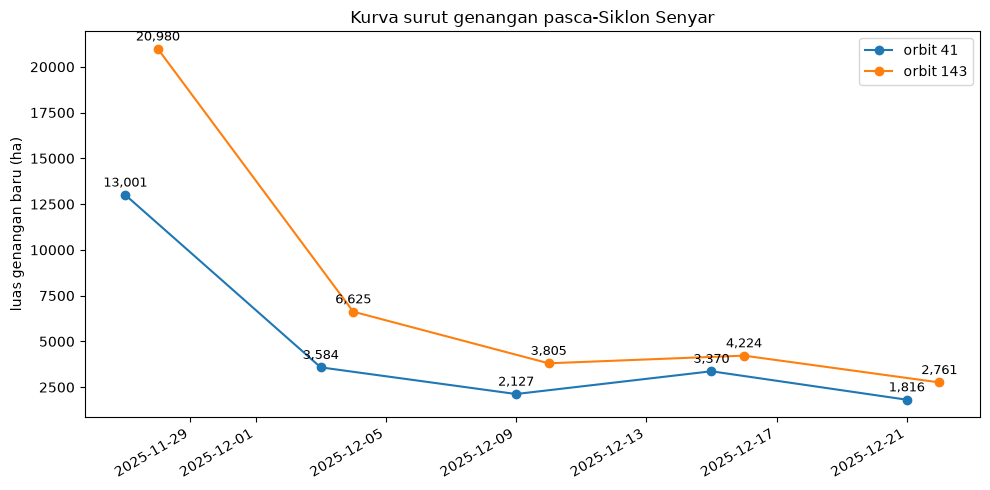

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))
for orbit, warna in ((41, "tab:blue"), (143, "tab:orange")):
    tgl = [date.fromisoformat(t) for t in DERET[orbit]]
    luas = [genangan[orbit, t].sum() * PX_HA for t in DERET[orbit]]
    ax.plot(tgl, luas, marker="o", color=warna, label=f"orbit {orbit}")
    for t, l in zip(tgl, luas):
        ax.annotate(f"{l:,.0f}", (t, l), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=9)
ax.set_ylabel("luas genangan baru (ha)")
ax.set_title("Kurva surut genangan pasca-Siklon Senyar")
ax.legend()
fig.autofmt_xdate()
plt.tight_layout()
plt.savefig(GAMBAR / "08-kurva-surut.png", dpi=110, bbox_inches="tight")
plt.show()

## Peta Durasi

Durasi per piksel dihitung dari scene saat banjir: piksel dianggap masih tergenang selama tergenang di semua scene sebelumnya juga. piksel yang kering di satu scene lalu basah lagi di scene berikutnya tidak dihitung sebagai lanjutan, karena itu kemungkinan genangan baru dari hujan susulan, bukan genangan yang sama

Peta gabungan memakai orbit 41 di area yang valid untuk orbit 41, sisanya orbit 143, sama seperti notebook utama

In [8]:
def durasi_orbit(orbit):
    deret = DERET[orbit]
    t0 = date.fromisoformat(deret[0])
    durasi = np.full(genangan[orbit, deret[0]].shape, -1, dtype="int16")  # -1 = tidak tergenang di tanggal awal
    masih = genangan[orbit, deret[0]].copy()
    durasi[masih] = 0
    for t in deret[1:]:
        masih &= genangan[orbit, t]
        durasi[masih] = (date.fromisoformat(t) - t0).days
    return durasi


dur41, dur143 = durasi_orbit(41), durasi_orbit(143)
v41 = genangan[41, DERET[41][0] + "_valid"]
durasi = np.where(v41, dur41, dur143)
tergenang = durasi >= 0

KELAS_DURASI = [(0, "< 6 hari"), (6, "6 sampai 11 hari"), (12, "12 sampai 17 hari"),
                (18, "18 sampai 23 hari"), (24, "24 hari atau lebih")]
print(f"{'durasi':<22}{'luas (ha)':>11}{'persen':>8}")
for d, nama in KELAS_DURASI:
    n = np.sum(durasi == d)
    print(f"{nama:<22}{n * PX_HA:>11,.0f}{n / tergenang.sum():>8.1%}")
print(f"{'total':<22}{tergenang.sum() * PX_HA:>11,.0f}")

durasi                  luas (ha)  persen
< 6 hari                   18,707   68.6%
6 sampai 11 hari            3,782   13.9%
12 sampai 17 hari             709    2.6%
18 sampai 23 hari             989    3.6%
24 hari atau lebih          3,098   11.4%
total                      27,285


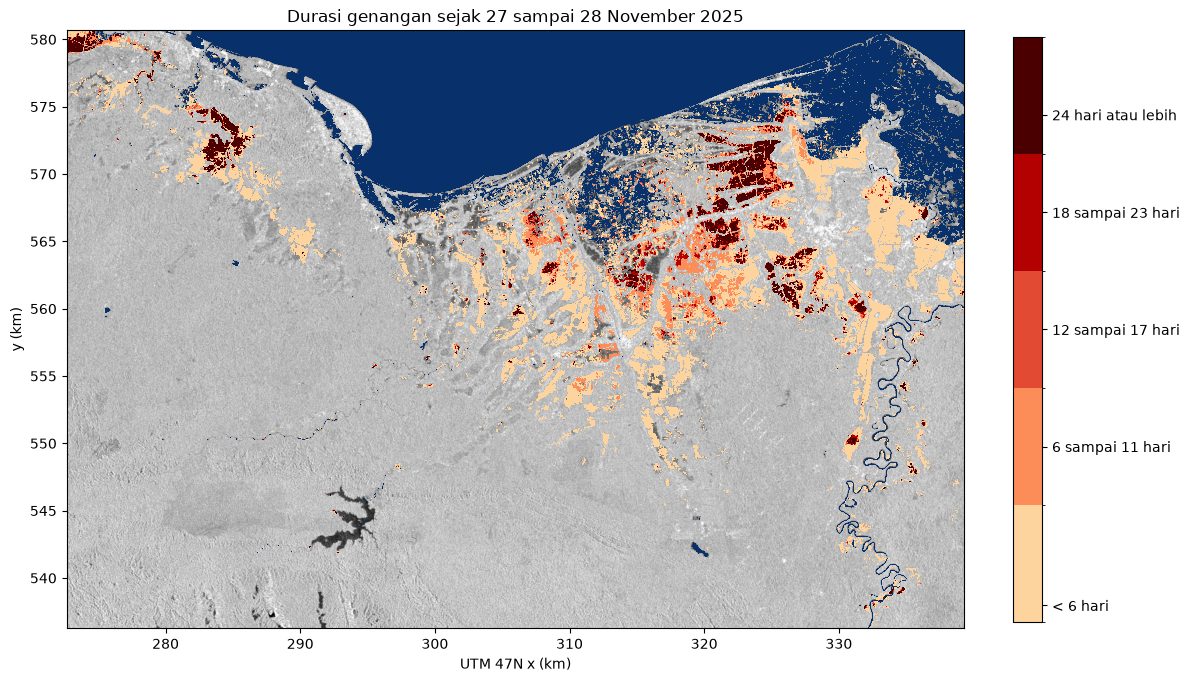

In [9]:
warna = ["#fdd49e", "#fc8d59", "#e34a33", "#b30000", "#4a0000"]
cmap = ListedColormap(warna)
norm = BoundaryNorm([-0.5, 3, 9, 15, 21, 30], cmap.N)
dasar = to_db(np.where(v41, s1[41, PRE[41]]["vv"], s1[143, PRE[143]]["vv"]))
fig, a = plt.subplots(figsize=(12, 8))
a.imshow(dasar, cmap="gray", vmin=-25, vmax=0, extent=EXTENT)
a.imshow(np.ma.masked_equal(air_permanen.astype("uint8"), 0), cmap=ListedColormap(["#08306b"]),
         extent=EXTENT, interpolation="nearest")
im = a.imshow(np.ma.masked_less(durasi, 0), cmap=cmap, norm=norm, extent=EXTENT, interpolation="nearest")
cb = plt.colorbar(im, ax=a, ticks=[0, 6, 12, 18, 24], fraction=0.03)
cb.ax.set_yticklabels([n for _, n in KELAS_DURASI])
a.set_title("Durasi genangan sejak 27 sampai 28 November 2025")
a.set_xlabel("UTM 47N x (km)")
a.set_ylabel("y (km)")
plt.tight_layout()
plt.savefig(GAMBAR / "09-peta-durasi-genangan.png", dpi=110, bbox_inches="tight")
plt.show()

## Durasi per Tutupan Lahan

In [10]:
print(f"{'kelas':<16}{'tergenang (ha)':>15}" + "".join(f"{n:>20}" for _, n in KELAS_DURASI))
for k, nama in KELAS.items():
    m = tergenang & (wc == k)
    if m.sum() * PX_HA < 50:
        continue
    baris = "".join(f"{np.sum(m & (durasi == d)) / m.sum():>20.1%}" for d, _ in KELAS_DURASI)
    print(f"{nama:<16}{m.sum() * PX_HA:>15,.0f}{baris}")

kelas            tergenang (ha)            < 6 hari    6 sampai 11 hari   12 sampai 17 hari   18 sampai 23 hari  24 hari atau lebih
pohon                     1,737               85.6%                7.7%                1.5%                1.1%                4.0%


rumput                    1,571               77.7%               12.5%                2.6%                1.1%                6.0%
lahan pertanian          23,162               66.4%               14.4%                2.7%                4.1%               12.5%


lahan terbuka               288               81.3%               15.8%                2.5%                0.3%                0.2%
lahan basah                 495               74.6%               15.3%                2.7%                1.5%                5.9%


## Pembahasan

Luas di tanggal saat banjir sama dengan notebook utama (13.001 ha orbit 41, 20.980 ha orbit 143, gabungan 27.285 ha), jadi deret waktu ini memakai peta awal yang sama

Genangan surut cepat. dalam enam hari luasnya turun ke 28% di orbit 41 (13.001 ke 3.584 ha) dan 32% di orbit 143 (20.980 ke 6.625 ha), dan 68,6% dari seluruh area tergenang sudah kering di scene kedua. sisanya menyusut lebih pelan, lalu naik lagi pada 15 sampai 16 Desember (2.127 ke 3.370 ha di orbit 41, 3.805 ke 4.224 ha di orbit 143) sebelum turun kembali. kenaikan ini tidak ikut menambah durasi, karena piksel yang sempat kering tidak dihitung sebagai genangan yang sama

Ada 3.098 ha (11,4%) yang tergenang di kelima scene, artinya 24 hari atau lebih. hampir semuanya lahan pertanian: 12,5% dari lahan pertanian yang tergenang masuk kelas ini, sementara kelas pohon hanya 4,0% dan lahan terbuka 0,2%. di peta, area ini berbentuk blok persegi dekat pesisir, bentuk yang khas petak sawah atau tambak

Bentuk itu juga yang membuat angka ini perlu hati hati. air yang bertahan 24 hari di petak persegi bisa genangan banjir yang tidak bisa keluar, tapi bisa juga petak yang memang sengaja digenangi, misalnya sawah yang diolah untuk musim tanam atau tambak yang tidak masuk kelas air permanen WorldCover 2021. citra radar saja tidak bisa membedakan keduanya. kenaikan luas pada 15 sampai 16 Desember juga bisa dari hujan susulan atau dari pengairan sawah. pembeda yang mungkin: membandingkan dengan kalender tanam setempat, atau memeriksa petak yang sama pada tanggal yang sama di tahun sebelumnya

Durasi di sini punya resolusi 6 hari, jadi "kurang dari 6 hari" berarti surut sebelum scene kedua tanpa tahu tepatnya kapan